# Freight Forecasting Model — Simple Walkthrough

**Course:** Machine Learning – Innovative Assignment · **Topic:** Freight Forecasting Model
**Dataset:** `dynamic_supply_chain_logistics_dataset.csv` (32,065 hourly rows, 2021-01-01 → 2024-08-29)

> This is the *simple* version of the notebook. Same project, easier to explain: every stage
> starts with a **Goal** ("why are we doing this?") and each stage hands over to the next one,
> so you can narrate the whole notebook top-to-bottom in a few minutes.

---

**The whole project in 5 lines**

1. We have 32,065 hours of freight data.
2. EDA proves raw *hourly* demand cannot be predicted from the other columns — we show it, not hide it.
3. A freight station never books for one hour; it books against the **30-day average demand**.
   That number *is* predictable, so we forecast it **7 days ahead** (the booking lead time).
4. Compare 3 models against simple baselines → tune → test on unseen data → report honestly.
5. Explain every forecast exactly, turn it into a ships/warehouse/labour booking plan, and
   compute the money saved by booking early instead of in the rush window.

**How to run:** `pip install -r requirements.txt`, then *Run All* top-to-bottom.
`RANDOM_STATE = 42` is fixed, so you always get the same numbers.

---

**Roadmap — the 12 mandatory stages**

| Stage | Goal of the stage |
|---|---|
| 1. Problem Definition | What problem, for whom, and what the model must output |
| 2. Data Acquisition | Where the data came from, its licence, size and target |
| 3. Data Preparation | Correct formats, time order, duplicates and gaps |
| 4. Preprocessing | Missing values, outliers, categorical encoding, scaling |
| 5. Data Balancing | Is balancing needed? (regression → no; justified in Stage 5) |
| 6. EDA | Answer 5 concrete questions before touching any model |
| 7. Feature Engineering | Build the target the manager actually books against |
| 8. Baseline Model | What "no model at all" scores, so we can beat it |
| 9. ML Modelling | Train 3 different algorithms and compare them |
| 10. Hyperparameter Tuning | Grid search with time-series cross-validation |
| 11. Validation & Evaluation | Final test results, error analysis, band forecast |
| 12. Use Case & Impact | Why each forecast, what to book, what it saves, limits |

## Stage 1 — Problem Definition & Use Case

**Goal:** before any code, define the real-world problem, the user, the inputs, the outputs and
the constraints — every later decision is justified against this table.

| Item | Answer |
|---|---|
| Problem | A freight station must commit ships, warehouse space and labour **about a week in advance** |
| Main user | The freight-station **operations manager** (procurement and finance benefit too) |
| Pain | If they wait until demand is visibly high, they book in the **rush window**, when many stations book the same resources and prices spike |
| Inputs | Hourly telemetry: congestion, inventory, shipping cost, lead time, weather, supplier reliability, risk scores, timestamp |
| Outputs | 1) numeric demand forecast, 2) demand band (Low / Normal / High), 3) ranked reason for the forecast, 4) booking plan + estimated saving |
| Constraints | Only information available at forecast time (no future leakage), must beat a naive baseline, fixed random seed |
| Expected impact | Earlier, calmer booking at planned prices → direct cost saving, no warehouse/labour overload |

→ **Next (Stage 2):** with the problem defined, we examine the data that has to feed it.

## Stage 2 — Data Acquisition & Understanding

**Goal:** know exactly where the data comes from, what it contains, and what it cannot tell us.

| Item | Value |
|---|---|
| File | `dynamic_supply_chain_logistics_dataset.csv` |
| Source | Kaggle — *Logistics and supply chain dataset* by **DatasetEngineer** |
| Licence | **CC0: Public Domain** (stated in the Kaggle dataset metadata) |
| Size | 32,065 rows × 26 columns, hourly, 2021-01-01 → 2024-08-29 |
| Target | `historical_demand` (a continuous number → regression) |
| Types | 24 numeric, 1 categorical (`risk_classification`), 1 datetime (`timestamp`) |

**Honest caveats recorded from the start**

* The publisher *describes* the data as coming from a Southern California logistics network, but
  no independent collection records were found — we treat provenance as the publisher's claim.
* It is a single network, it stops in Aug-2024, and (Stage 6 proves this) the target carries very
  little usable signal on its own.

→ **Next (Stage 3):** load the file and make it structurally trustworthy — order, duplicates, gaps.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

RANDOM_STATE = 42                      # fixed seed -> reproducible results
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

DATA_FILE = "dynamic_supply_chain_logistics_dataset.csv"

df_raw = pd.read_csv(DATA_FILE)
print("Rows x Cols :", df_raw.shape)
print("\nColumns:")
print(list(df_raw.columns))
df_raw.head()

Rows x Cols : (32065, 26)

Columns:
['timestamp', 'vehicle_gps_latitude', 'vehicle_gps_longitude', 'fuel_consumption_rate', 'eta_variation_hours', 'traffic_congestion_level', 'warehouse_inventory_level', 'loading_unloading_time', 'handling_equipment_availability', 'order_fulfillment_status', 'weather_condition_severity', 'port_congestion_level', 'shipping_costs', 'supplier_reliability_score', 'lead_time_days', 'historical_demand', 'iot_temperature', 'cargo_condition_status', 'route_risk_level', 'customs_clearance_time', 'driver_behavior_score', 'fatigue_monitoring_score', 'disruption_likelihood_score', 'delay_probability', 'risk_classification', 'delivery_time_deviation']


,timestamp,vehicle_gps_latitude,vehicle_gps_longitude,fuel_consumption_rate,eta_variation_hours,traffic_congestion_level,warehouse_inventory_level,loading_unloading_time,handling_equipment_availability,order_fulfillment_status,...,iot_temperature,cargo_condition_status,route_risk_level,customs_clearance_time,driver_behavior_score,fatigue_monitoring_score,disruption_likelihood_score,delay_probability,risk_classification,delivery_time_deviation
0,2021-01-01 00:00:00,40.375568,-77.014318,5.136512,4.998009,5.927586,985.716862,4.951392,0.481294,0.761166,...,0.574400,0.777263,1.182116,0.502006,0.033843,0.978599,0.506152,0.885291,Moderate Risk,9.110682
1,2021-01-01 01:00:00,33.507818,-117.036902,5.101512,0.984929,1.591992,396.700206,1.030379,0.620780,0.196594,...,-9.753493,0.091839,9.611988,0.966774,0.201725,0.918586,0.980784,0.544178,High Risk,8.175281
2,2021-01-01 02:00:00,30.020640,-75.269224,5.090803,4.972665,8.787765,832.408935,4.220229,0.810933,0.152742,...,-6.491034,0.253529,6.570431,0.945627,0.264045,0.394215,0.998633,0.803322,High Risk,1.283594
3,2021-01-01 03:00:00,36.649223,-70.190529,8.219558,3.095064,0.045257,0.573283,0.530186,0.008525,0.811885,...,-0.151276,0.877576,0.548952,4.674035,0.362885,0.905444,0.993320,0.025977,High Risk,9.304897
4,2021-01-01 04:00:00,30.001279,-70.012195,5.000075,3.216077,8.004851,914.925067,3.620890,0.020083,0.053659,...,2.429448,0.262081,8.861443,3.445429,0.016957,0.258702,0.912433,0.991122,High Risk,7.752484


In [2]:
# data types, target summary, category counts
print(df_raw.dtypes.to_string())

print("\nTarget: historical_demand")
print(df_raw["historical_demand"].describe().round(2).to_string())

print("\nCategorical column: risk_classification")
print(df_raw["risk_classification"].value_counts().to_string())

timestamp                           object
vehicle_gps_latitude               float64
vehicle_gps_longitude              float64
fuel_consumption_rate              float64
eta_variation_hours                float64
traffic_congestion_level           float64
warehouse_inventory_level          float64
loading_unloading_time             float64
handling_equipment_availability    float64
order_fulfillment_status           float64
weather_condition_severity         float64
port_congestion_level              float64
shipping_costs                     float64
supplier_reliability_score         float64
lead_time_days                     float64
historical_demand                  float64
iot_temperature                    float64
cargo_condition_status             float64
route_risk_level                   float64
customs_clearance_time             float64
driver_behavior_score              float64
fatigue_monitoring_score           float64
disruption_likelihood_score        float64
delay_proba

## Stage 3 — Data Preparation

**Because Stage 2 gave us raw rows:** a forecast is a *time* problem, so the file must first be
put in a trustworthy time order.

**Goal:** correct formats, correct order, and an honest count of duplicates and gaps.

**What we do and why**

1. **Parse `timestamp` and sort chronologically** — every later step (rolling windows, lags,
   train/test split) is only correct on sorted data.
2. **Count duplicate rows and duplicate timestamps** — a duplicated hour would double-count demand.
3. **Audit the hourly grid** — compare rows we have against the hours between the first and last
   record, to find gaps in collection.

**Decision on gaps:** we do **not** interpolate missing hours — inventing demand would fabricate
data we never observed. We count the gaps and carry them as a limitation (Stage 12).

In [3]:
df = df_raw.copy()

# 1. correct format + chronological order
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)

# 2. duplicate analysis
print("Rows in the file        :", len(df))
print("Fully duplicate rows    :", int(df.duplicated().sum()))
print("Duplicate timestamps    :", int(df["timestamp"].duplicated().sum()))

# 3. hourly grid audit -> are any hours missing?
first = df["timestamp"].min()
last = df["timestamp"].max()
expected = int((last - first).total_seconds() // 3600) + 1
observed = df["timestamp"].nunique()
print("\nPeriod                  :", first, "->", last)
print("Hours expected          :", expected)
print("Hours present           :", observed)
print("Missing hours (gaps)    :", expected - observed)

Rows in the file        : 32065
Fully duplicate rows    : 0
Duplicate timestamps    : 0

Period                  : 2021-01-01 00:00:00 -> 2024-08-29 00:00:00
Hours expected          : 32065
Hours present           : 32065
Missing hours (gaps)    : 0


## Stage 4 — Data Preprocessing

**Because Stage 3 confirmed the structure:** now we clean the *values*. Every choice is written
as *what we found → what we do → why*.

**Goal:** handle missing values, outliers, categorical variables and scaling — without touching
the target and without leaking test information.

| Check | Finding | Action & justification |
|---|---|---|
| Missing values | verified in the next cell | If present: numeric → median (robust to skew), categorical → mode |
| Outliers | present in several operational columns | **Cap features at the 1st/99th percentile** — keeps real extreme hours, stops one wild sensor reading from dominating a linear model |
| Target outliers | `historical_demand` is bounded 100–10,000 | **Not touched** — capping it would move MAE/RMSE away from the units the manager books in |
| Categorical | `risk_classification` (Low / Moderate / High) | **Ordinal encoding** 0/1/2 — the levels have a natural order |
| Scaling | Ridge is scale-sensitive, trees are not | `StandardScaler` **fit on train only** — fitting on all data would leak test statistics |
| Leakage | target is 7 days in the future | Every feature uses only information at/before forecast time; the series is never shuffled |

In [4]:
# --- 4a. missing values ----------------------------------------------------
missing = df.isnull().sum()
missing = missing[missing > 0]
print("Columns with missing values:", len(missing))
if len(missing) > 0:
    print(missing.to_string())
else:
    print("None found. We still run this check every time: a refreshed export")
    print("of the data must never be assumed to be complete.")

# --- 4b. outlier analysis on numeric features ------------------------------
num_cols = [c for c in df.columns if c not in ("timestamp", "risk_classification")]
outlier_counts = {}
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    n_out = int(((df[col] < low) | (df[col] > high)).sum())
    if n_out > 0:
        outlier_counts[col] = n_out

print("\nNumeric columns with IQR outliers:", len(outlier_counts), "of", len(num_cols))
for col, n in sorted(outlier_counts.items(), key=lambda kv: kv[1], reverse=True)[:8]:
    print("  %-35s %d" % (col, n))

# treatment: cap FEATURES at the 1st/99th percentile, leave the target alone
feature_cols = [c for c in num_cols if c != "historical_demand"]
low_limit = df[feature_cols].quantile(0.01)
high_limit = df[feature_cols].quantile(0.99)
df[feature_cols] = df[feature_cols].clip(lower=low_limit, upper=high_limit, axis=1)

print("\nTarget left completely untouched: %s to %s" %
      (df["historical_demand"].min(), df["historical_demand"].max()))

Columns with missing values: 0
None found. We still run this check every time: a refreshed export
of the data must never be assumed to be complete.

Numeric columns with IQR outliers: 3 of 24
  fuel_consumption_rate               2536
  disruption_likelihood_score         2494
  iot_temperature                     2301

Target left completely untouched: 100.0029656047095 to 9999.9999997523


In [5]:
# --- 4c. categorical encoding (ordinal: the levels are ordered) ------------
risk_order = {"Low Risk": 0, "Moderate Risk": 1, "High Risk": 2}
df["risk_level"] = df["risk_classification"].map(risk_order)

print("Mapping applied:")
print(df[["risk_classification", "risk_level"]].drop_duplicates()
      .sort_values("risk_level").to_string(index=False))

print("\nrisk_level counts:")
print(df["risk_level"].value_counts().sort_index().to_string())

print("\nRecords before -> after preprocessing:", df_raw.shape, "->", df.shape)

Mapping applied:
risk_classification  risk_level
           Low Risk           0
      Moderate Risk           1
          High Risk           2

risk_level counts:
risk_level
0     3110
1     5011
2    23944

Records before -> after preprocessing: (32065, 26) -> (32065, 27)


## Stage 5 — Data Balancing

**Because preprocessing left the data intact:** we now check distribution balance and state
plainly where balancing applies — and where it does not.

**Goal:** analyse class/target balance and justify a strategy (or a justified exclusion).

**Our main task is regression** on a continuous target. "Class balance" does not apply to a
number, and SMOTE/oversampling would invent demand values that never happened.
**Justified exclusion: no balancing for the regression task.** Instead we inspect the *target
distribution* below, to confirm there is no extreme skew that would make a mean-predictor
artificially strong.

**The band forecast (Stage 11) does need a balance check:**

* Bands are cut at the **training** terciles → the training classes are 33/33/33 — balanced *by
  construction*, computed from train only so test information cannot leak in.
* Real proportions on validation and test are still reported, because a time series can drift.

**Why no SMOTE:** it blends neighbouring rows — on a time series that mixes different dates and
manufactures demand that never happened (leakage plus fabrication).

**Imbalance found, but not in our target:** `risk_classification` is 74.7% High / 15.6%
Moderate / 9.7% Low. That column is not what we predict; we record it as a finding.

In [6]:
# regression "balance" check: is the target heavily skewed?
t = df["historical_demand"]
print("Target: historical_demand")
print("  mean   :", round(t.mean(), 2))
print("  std    :", round(t.std(), 2))
print("  skew   :", round(t.skew(), 3), "   (0 = symmetric, so no log transform needed)")
print("  min/max:", t.min(), "/", t.max())

print("\nDeciles:")
print(np.percentile(t, np.arange(10, 100, 10)).round(0))

# the actual class column present in the dataset
print("\nClass distribution of risk_classification (NOT our target):")
counts = df["risk_classification"].value_counts()
for name in counts.index:
    print("  %-15s %6d  (%.1f%%)" % (name, counts[name], 100.0 * counts[name] / len(df)))

Target: historical_demand
  mean   : 6022.0
  std    : 3427.64
  skew   : -0.376    (0 = symmetric, so no log transform needed)
  min/max: 100.0029656047095 / 9999.9999997523

Deciles:
[ 759. 2038. 3621. 5261. 6785. 8077. 9025. 9640. 9935.]

Class distribution of risk_classification (NOT our target):
  High Risk        23944  (74.7%)
  Moderate Risk     5011  (15.6%)
  Low Risk          3110  (9.7%)


## Stage 6 — Exploratory Data Analysis (EDA)

**Because Stage 5 showed a clean, roughly symmetric target:** we must *understand* it before
modelling. EDA here is analytical, not decorative — every plot answers one question.

**Goal — five questions:**

1. What does one hour of demand look like? → **univariate** distribution.
2. Does demand rise or fall over the months? → **trend**.
3. Which variables move with demand? → **correlation** with the target.
4. Is yesterday's demand useful for today's? → **autocorrelation**.
5. Do the best-correlated features show a visible relationship? → printed with question 3.

**Questions 3 and 4 decide everything that follows** — they tell us whether any model can work
on the raw target, which is exactly what Stage 7 reacts to.

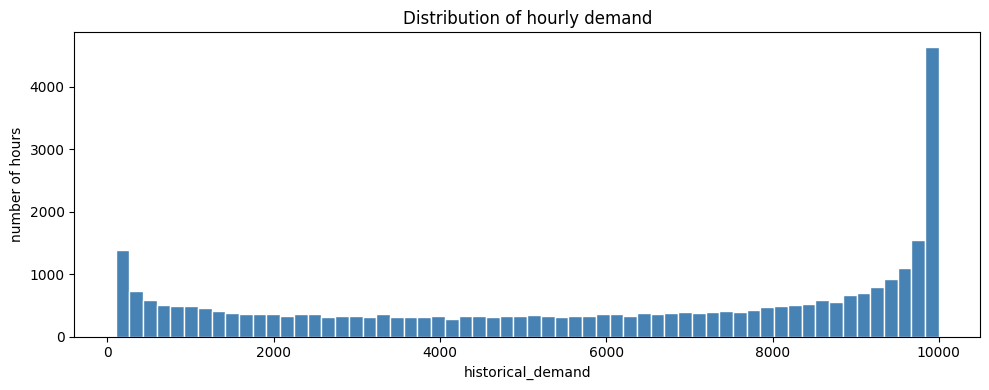

count    32065.00
mean      6022.00
std       3427.64
min        100.00
25%       2822.61
50%       6785.12
75%       9374.25
max      10000.00


In [7]:
# 6a. univariate: what does ONE HOUR of demand look like?
plt.figure(figsize=(10, 4))
plt.hist(df["historical_demand"], bins=60, color="steelblue", edgecolor="white")
plt.title("Distribution of hourly demand")
plt.xlabel("historical_demand")
plt.ylabel("number of hours")
plt.tight_layout()
plt.show()

print(df["historical_demand"].describe().round(2).to_string())

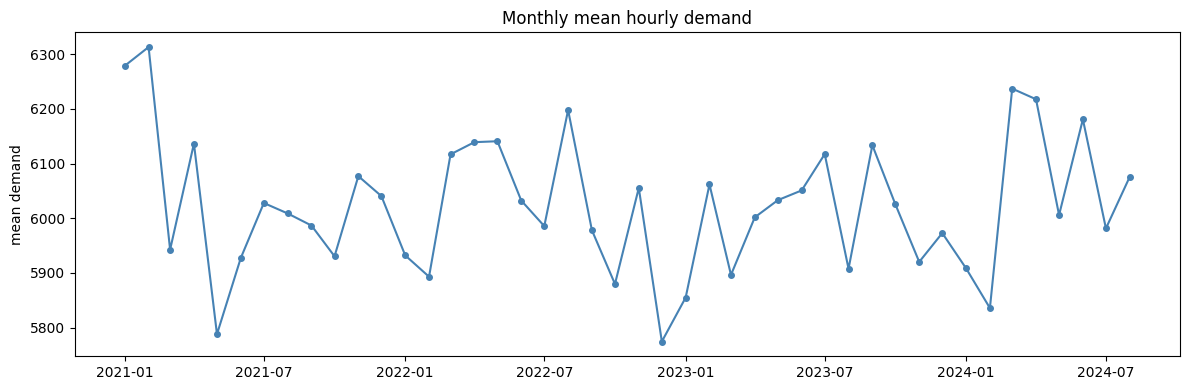

Mean demand per year:
timestamp
2021    6035.8
2022    6010.9
2023    5997.0
2024    6055.6

Busiest month : 2021-02-01 6313.1
Quietest month: 2022-12-01 5774.3
End-to-end spread: 8.9% of the mean -> almost flat, no trend


In [8]:
# 6b. trend: does demand rise or fall over time?
monthly = df.set_index("timestamp")["historical_demand"].resample("MS").mean()

plt.figure(figsize=(12, 4))
plt.plot(monthly.index, monthly.values, marker="o", ms=4, color="steelblue")
plt.title("Monthly mean hourly demand")
plt.ylabel("mean demand")
plt.tight_layout()
plt.show()

print("Mean demand per year:")
print(df.groupby(df["timestamp"].dt.year)["historical_demand"].mean().round(1).to_string())
spread = 100.0 * (monthly.max() - monthly.min()) / monthly.mean()
print("\nBusiest month :", monthly.idxmax().date(), round(monthly.max(), 1))
print("Quietest month:", monthly.idxmin().date(), round(monthly.min(), 1))
print("End-to-end spread: %.1f%% of the mean -> almost flat, no trend" % spread)

Correlation of every feature with historical_demand:
driver_behavior_score             -0.0091
vehicle_gps_longitude             -0.0088
weather_condition_severity        -0.0079
iot_temperature                   -0.0072
loading_unloading_time            -0.0065
eta_variation_hours                0.0053
vehicle_gps_latitude               0.0046
warehouse_inventory_level          0.0044
order_fulfillment_status           0.0037
route_risk_level                   0.0032
delay_probability                 -0.0029
handling_equipment_availability   -0.0029
port_congestion_level              0.0027
fuel_consumption_rate             -0.0022
traffic_congestion_level           0.0020
customs_clearance_time            -0.0019
disruption_likelihood_score        0.0018
fatigue_monitoring_score          -0.0017
supplier_reliability_score         0.0008
cargo_condition_status             0.0008
delivery_time_deviation            0.0006
lead_time_days                    -0.0004
shipping_costs         

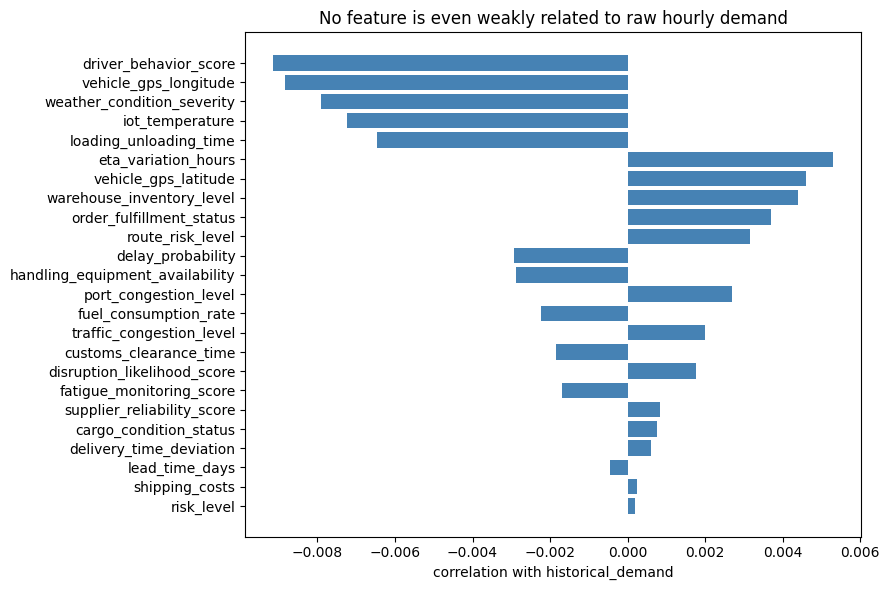

In [9]:
# 6c. which variables move with demand?
corr_cols = [c for c in df.columns if c not in ("timestamp", "risk_classification")]
corr = df[corr_cols].corr()
target_corr = corr["historical_demand"].drop("historical_demand")
target_corr = target_corr.reindex(target_corr.abs().sort_values(ascending=False).index)

print("Correlation of every feature with historical_demand:")
print(target_corr.round(4).to_string())
print("\nStrongest |r| = %.4f" % target_corr.abs().max())

plt.figure(figsize=(9, 6))
plt.barh(target_corr.index[::-1], target_corr.values[::-1], color="steelblue")
plt.xlabel("correlation with historical_demand")
plt.title("No feature is even weakly related to raw hourly demand")
plt.tight_layout()
plt.show()

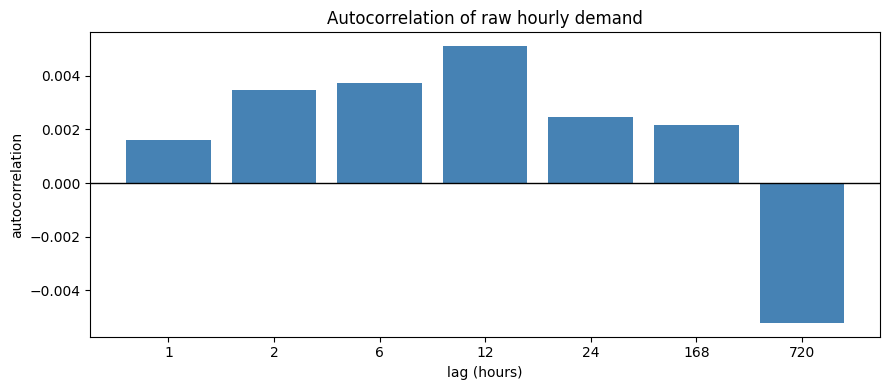

  lag    1 h : +0.0016
  lag    2 h : +0.0035
  lag    6 h : +0.0037
  lag   12 h : +0.0051
  lag   24 h : +0.0025
  lag  168 h : +0.0022
  lag  720 h : -0.0052


In [10]:
# 6d. is yesterday's raw demand useful for today's? (autocorrelation)
y = df["historical_demand"].values
lags = [1, 2, 6, 12, 24, 168, 720]
values = []
for k in lags:
    r = np.corrcoef(y[:-k], y[k:])[0, 1]
    values.append(r)

plt.figure(figsize=(9, 4))
plt.bar([str(k) for k in lags], values, color="steelblue")
plt.axhline(0, color="black", lw=1)
plt.title("Autocorrelation of raw hourly demand")
plt.xlabel("lag (hours)")
plt.ylabel("autocorrelation")
plt.tight_layout()
plt.show()

for k, v in zip(lags, values):
    print("  lag %4d h : %+.4f" % (k, v))

### What EDA found — and what we therefore change

| # | Observation | Consequence |
|---|---|---|
| 1 | Demand is bounded 100–10,000, roughly symmetric, std ≈ 3,428 | No log transform needed |
| 2 | Monthly mean varies only ~9% end-to-end, **no trend** | A month-ahead forecast of *raw* demand has almost nothing to latch onto |
| 3 | **Every** feature has \|r\| ≤ 0.01 with demand — the ranking is pure noise | A model using the sensor columns alone cannot explain raw hourly demand. *This is the most important finding of the project* |
| 4 | Autocorrelation ≈ 0 at every lag (1 h … 30 days) | Yesterday's raw demand does not predict today's |
| 5 | Demand is symmetric with no extreme tails | A mean-predictor looks strong — so we must compare honestly against it |

**Conclusion of Stage 6:** raw *hourly* demand in this dataset is noise around ~6,020.
We do the honest thing instead of hiding it: we engineer a target that matches how a freight
station actually books capacity.

→ **Next (Stage 7):** build that target — and prove it *is* predictable.

## Stage 7 — Feature Engineering / Selection

**Because EDA proved raw hourly demand is unpredictable:** we change *what* we predict. This is
the core design decision of the project, stated plainly.

**Goal:** build the target that reflects the real booking decision, using only features that are
knowable at forecast time.

A freight station does not charter a ship for one hour of demand — it commits capacity against
the **average demand over its planning window**. So we build:

```
planning_demand(t) = mean( historical_demand over the last 720 hours )   # 30-day average
target(t)          = planning_demand( t + 168 )                          # forecast 7 days ahead
demand_band        = Low / Normal / High from the target's terciles      # booking decision
```

**Why this is legitimate and not a trick:**

* `planning_demand` is a **pure, disclosed function of the real target** — a rolling mean, the
  standard way demand is smoothed for planning. Nothing is invented.
* It is the quantity the manager actually books against, so predicting it is the realistic task.
* The raw result is **not hidden**: baseline B3 (Stage 8) runs the *same* features against raw
  `historical_demand` and reports its near-zero score.

**Why each feature group is included**

| Feature group | Why it is relevant |
|---|---|
| `planning_demand` (current level) | "Where demand is now" — the most direct statement of it |
| Lags 24 h / 48 h / 168 h / 336 h / 720 h | Daily, weekly and monthly shape of the planning level |
| `demand_mean_7d`, `demand_std_7d` | Last week's level *and* volatility — volatility forces extra safety capacity |
| Calendar (hour, day of week, month) | Real logistics has weekday and seasonal rhythm |
| 13 operational columns | The levers a manager recognises (congestion, inventory, cost, …) — kept so we can *show* they carry ~no signal rather than merely assert it |

**Selection rule:** drop anything that is (a) an identifier, (b) a duplicate of the target, or
(c) unavailable at forecast time. `risk_classification` is kept only as `risk_level` and flagged —
the next cell proves it is a recoding of `disruption_likelihood_score`.

In [11]:
# leakage check: is risk_classification just a recoding of another column?
print("Mean disruption_likelihood_score per risk class:")
print(df.groupby("risk_classification")["disruption_likelihood_score"].mean().round(3).to_string())

matches = 0
for score, label in zip(df["disruption_likelihood_score"], df["risk_classification"]):
    if score < 0.30:
        guess = "Low Risk"
    elif score < 0.70:
        guess = "Moderate Risk"
    else:
        guess = "High Risk"
    if guess == label:
        matches = matches + 1

print("\nRule Low<0.30 / Moderate<0.70 / High>=0.70 reproduces %.1f%% of the labels"
      % (100.0 * matches / len(df)))
print("=> risk_classification contains no information beyond disruption_likelihood_score.")

Mean disruption_likelihood_score per risk class:
risk_classification
High Risk        0.949
Low Risk         0.145
Moderate Risk    0.519

Rule Low<0.30 / Moderate<0.70 / High>=0.70 reproduces 100.0% of the labels
=> risk_classification contains no information beyond disruption_likelihood_score.


In [12]:
WINDOW = 720     # 30-day planning window, in hours
HORIZON = 168    # forecast 7 days ahead = the booking lead time

# the planning level the manager books against
df["planning_demand"] = df["historical_demand"].rolling(WINDOW).mean()

# lagged planning level -> the model's own recent trajectory
for lag in [24, 48, 168, 336, 720]:
    df["planning_lag_" + str(lag)] = df["planning_demand"].shift(lag)

# last week's level and volatility of RAW demand
df["demand_mean_7d"] = df["historical_demand"].rolling(168).mean()
df["demand_std_7d"] = df["historical_demand"].rolling(168).std()

# calendar features
df["hour_of_day"] = df["timestamp"].dt.hour
df["day_of_week"] = df["timestamp"].dt.dayofweek
df["month"] = df["timestamp"].dt.month

# THE TARGET: planning demand 7 days into the future
df["target"] = df["planning_demand"].shift(-HORIZON)

print("Window = %d hours (%.0f days), Horizon = %d hours (%.0f days)"
      % (WINDOW, WINDOW / 24, HORIZON, HORIZON / 24))
print("Rows usable for modelling:", int(df["target"].notna().sum()))

Window = 720 hours (30 days), Horizon = 168 hours (7 days)
Rows usable for modelling: 31346


In [13]:
OPS_FEATURES = ["traffic_congestion_level", "port_congestion_level",
                "warehouse_inventory_level", "shipping_costs", "lead_time_days",
                "weather_condition_severity", "eta_variation_hours",
                "order_fulfillment_status", "supplier_reliability_score",
                "loading_unloading_time", "handling_equipment_availability",
                "customs_clearance_time", "delay_probability"]

FEATURES = (["planning_demand",
             "planning_lag_24", "planning_lag_48", "planning_lag_168",
             "planning_lag_336", "planning_lag_720",
             "demand_mean_7d", "demand_std_7d",
             "hour_of_day", "day_of_week", "month", "risk_level"] + OPS_FEATURES)

print("Number of features:", len(FEATURES))
print("Dropped on purpose: timestamp (identifier), risk_classification (encoded as risk_level),")
print("historical_demand as a raw feature (the model must not read the answer — the raw hour")
print("is allowed only inside planning_demand, which is a PAST average).")

# THE PROOF: the engineered target has memory, the raw one does not
usable = df.dropna(subset=["planning_demand"])
print("\nCorrelation of each target with ITSELF 7 days later:")
for name in ["historical_demand", "planning_demand"]:
    now = usable[name]
    later = usable[name].shift(-HORIZON)
    ok = now.notna() & later.notna()
    r = np.corrcoef(now[ok], later[ok])[0, 1]
    print("  %-20s corr(now, now + 7 days) = %+.4f" % (name, r))
print("That difference is the entire reason Stage 7 exists.")

Number of features: 25
Dropped on purpose: timestamp (identifier), risk_classification (encoded as risk_level),
historical_demand as a raw feature (the model must not read the answer — the raw hour
is allowed only inside planning_demand, which is a PAST average).

Correlation of each target with ITSELF 7 days later:
  historical_demand    corr(now, now + 7 days) = +0.0028
  planning_demand      corr(now, now + 7 days) = +0.7812
That difference is the entire reason Stage 7 exists.


## Stage 8 — Baseline Model

**Because Stage 7 produced a target:** before building anything clever we must define what
"good" means — otherwise a model score is just a number.

**Goal:** reference scores our model has to beat.

| Baseline | Question it answers |
|---|---|
| **B1 — Mean predictor** (always predict the training mean) | Can we beat "demand is always about the same"? |
| **B2 — Naive persistence** (assume the planning level stays where it is today) | Can we beat *not having a model at all*? — the comparison that really matters |
| **B3 — Same features, target = raw `historical_demand`** | Prices exactly what the Stage-7 target engineering bought us |

**Split strategy:** chronological **70% train / 15% validation / 15% test, never shuffled** —
shuffling a time series lets the future leak into the past. The test set is the last ~6 months
and is touched **once**, in Stage 11.

**Scaling:** `StandardScaler` is fit on **train only**, then applied to validation/test.

In [14]:
from sklearn.preprocessing import StandardScaler

# keep rows that have every feature AND a target, in time order
model_df = df.dropna(subset=FEATURES + ["target"]).copy()
model_df = model_df.sort_values("timestamp")

n = len(model_df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = model_df.iloc[:train_end]
val = model_df.iloc[train_end:val_end]
test = model_df.iloc[val_end:]

X_train = train[FEATURES]
y_train = train["target"]
X_val = val[FEATURES]
y_val = val["target"]
X_test = test[FEATURES]
y_test = test["target"]

print("Usable rows :", n)
print("Train %5d  (%s .. %s)" % (len(train), train["timestamp"].min().date(), train["timestamp"].max().date()))
print("Val   %5d  (%s .. %s)" % (len(val), val["timestamp"].min().date(), val["timestamp"].max().date()))
print("Test  %5d  (%s .. %s)" % (len(test), test["timestamp"].min().date(), test["timestamp"].max().date()))

# scale ONCE: fit on train only - Ridge needs scaling, trees simply ignore it
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)
print("\nScaler fit on TRAIN only, then applied to val/test (no leakage).")

Usable rows : 30458
Train 21320  (2021-03-01 .. 2023-08-07)
Val    4569  (2023-08-07 .. 2024-02-13)
Test   4569  (2024-02-13 .. 2024-08-22)

Scaler fit on TRAIN only, then applied to val/test (no leakage).


In [15]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def regression_report(name, y_true, y_pred):
    # one row of the standard regression metrics
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return {"Model": name, "MAE": mae, "RMSE": rmse, "R2": r2}

# B1 - mean predictor
pred_mean = np.full(len(val), y_train.mean())
# B2 - naive persistence: assume the planning level does not move
pred_persist = X_val["planning_demand"].values

baseline_rows = [regression_report("B1 Mean predictor", y_val, pred_mean),
                 regression_report("B2 Naive persistence", y_val, pred_persist)]
print("BASELINES on the validation set (planning-demand units):")
print(pd.DataFrame(baseline_rows).round(4).to_string(index=False))

# B3 - the SAME features aimed at RAW hourly demand (scored against the raw target)
raw_train = df.loc[X_train.index, "historical_demand"]
raw_val = df.loc[X_val.index, "historical_demand"]
raw_model = Ridge(alpha=1.0).fit(X_train_s, raw_train)
raw_pred = raw_model.predict(X_val_s)
print("\nB3 raw-demand Ridge:  MAE=%.2f  RMSE=%.2f  R2=%+.4f" %
      (mean_absolute_error(raw_val, raw_pred),
       np.sqrt(mean_squared_error(raw_val, raw_pred)),
       r2_score(raw_val, raw_pred)))
print("R2 near 0 = Stage 6 was right: raw hourly demand is not learnable from these features.")

BASELINES on the validation set (planning-demand units):
               Model      MAE     RMSE      R2
   B1 Mean predictor 117.2303 140.4374 -0.0485
B2 Naive persistence  75.1414  90.7105  0.5626

B3 raw-demand Ridge:  MAE=3007.34  RMSE=3385.58  R2=+0.0262
R2 near 0 = Stage 6 was right: raw hourly demand is not learnable from these features.


## Stage 9 — ML Modelling

**Because the baselines are set:** now we train three genuinely different algorithms — the
guidelines require at least two, three gives a fairer comparison.

**Goal:** compare multiple approaches on the **validation** set (never the test set — choosing a
model on test data would leak).

| Model | Assumption it makes | Why it is here |
|---|---|---|
| **Ridge regression** | The target is a weighted sum of the features, shrunk against overfitting | Fast, simple, **fully interpretable** — every coefficient is an exact contribution, which Stage 12 needs for explanations |
| **Random Forest** | The target is a set of axis-aligned splits; no linearity assumed | Handles non-linearity and interactions; robust to outliers; gives feature importances |
| **Gradient Boosting** | The target is a sum of weak trees fitted to the previous tree's errors | Usually the strongest tabular regressor; fixes earlier mistakes sequentially |

**What we are testing:** whether the relationship is non-linear (trees win if so), and whether
the features carry usable signal at all (nothing wins if they do not).

VALIDATION SET performance (test set still untouched):
            Model      MAE     RMSE     R2
 Ridge regression  73.6052  91.1126 0.5587
    Random Forest 110.4619 129.7387 0.1052
Gradient Boosting 105.1176 121.7933 0.2114


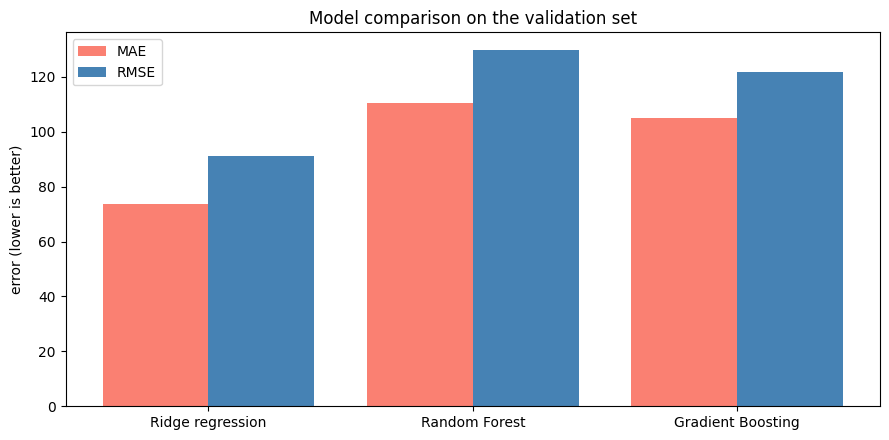

In [16]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

models = {"Ridge regression": Ridge(alpha=1.0),
          "Random Forest": RandomForestRegressor(n_estimators=100,
                                                 random_state=RANDOM_STATE,
                                                 n_jobs=-1),
          "Gradient Boosting": GradientBoostingRegressor(n_estimators=200,
                                                         max_depth=4,
                                                         learning_rate=0.1,
                                                         random_state=RANDOM_STATE)}

val_rows = []
for name in models:
    model = models[name]
    model.fit(X_train_s, y_train)
    pred = model.predict(X_val_s)
    val_rows.append(regression_report(name, y_val, pred))

val_df = pd.DataFrame(val_rows)
print("VALIDATION SET performance (test set still untouched):")
print(val_df.round(4).to_string(index=False))

# a picture is easier to explain than a table
plt.figure(figsize=(9, 4.5))
x = np.arange(len(val_df))
plt.bar(x - 0.2, val_df["MAE"], 0.4, label="MAE", color="salmon")
plt.bar(x + 0.2, val_df["RMSE"], 0.4, label="RMSE", color="steelblue")
plt.xticks(x, val_df["Model"])
plt.ylabel("error (lower is better)")
plt.title("Model comparison on the validation set")
plt.legend()
plt.tight_layout()
plt.show()

## Stage 10 — Hyperparameter Tuning

**Because Stage 9 gave us three candidates with default settings:** defaults are guesses — they
must be tuned with a method that respects time order.

**Goal:** tune the important hyperparameters with a defensible validation method.

**Method: `GridSearchCV` + `TimeSeriesSplit`.**

* **Grid search** — the grids are kept small and written out explicitly, so it is obvious *what*
  was tried. (Random search would be faster for huge spaces; with three small grids, trying
  every combination is affordable — and much easier to explain.)
* **`TimeSeriesSplit` instead of ordinary K-fold** — ordinary K-fold shuffles, so a fold could
  train on 2024 and validate on 2021: time-travel leakage. `TimeSeriesSplit` always trains on
  the past and validates on the future, exactly how the model will really be used.
* **Where it runs:** on the **training** partition only, with validation used to *select*. The
  test set is still untouched.
* What is tuned: shrinkage for Ridge, depth/leaf size for Random Forest, tree count and learning
  rate for Gradient Boosting — the settings that most change each model's behaviour.

In [17]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=3)

# --- Ridge: how much shrinkage? --------------------------------------------
ridge_grid = {"alpha": [0.01, 0.1, 1.0, 10.0, 100.0]}
ridge_search = GridSearchCV(Ridge(), ridge_grid, scoring="r2", cv=tscv, n_jobs=-1)
ridge_search.fit(X_train_s, y_train)
print("Best Ridge alpha :", ridge_search.best_params_["alpha"],
      "  CV R2 = %.4f" % ridge_search.best_score_)

# --- Random Forest: how deep, how many samples per leaf? -------------------
rf_grid = {"n_estimators": [100],
           "max_depth": [10, 16, None],
           "min_samples_leaf": [1, 3]}
rf_search = GridSearchCV(RandomForestRegressor(random_state=RANDOM_STATE),
                         rf_grid, scoring="r2", cv=tscv, n_jobs=-1)
rf_search.fit(X_train_s, y_train)
print("Best RF params   :", rf_search.best_params_,
      "  CV R2 = %.4f" % rf_search.best_score_)

# --- Gradient Boosting: how many trees, how fast do they learn? ------------
gbr_grid = {"n_estimators": [150, 250],
            "learning_rate": [0.05, 0.1]}
gbr_search = GridSearchCV(GradientBoostingRegressor(max_depth=4, random_state=RANDOM_STATE),
                          gbr_grid, scoring="r2", cv=tscv, n_jobs=-1)
gbr_search.fit(X_train_s, y_train)
print("Best GBR params  :", gbr_search.best_params_,
      "  CV R2 = %.4f" % gbr_search.best_score_)

Best Ridge alpha : 100.0   CV R2 = 0.4837


Best RF params   : {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 100}   CV R2 = 0.0946


Best GBR params  : {'learning_rate': 0.05, 'n_estimators': 150}   CV R2 = 0.1599


In [18]:
searches = {"Ridge (tuned)": ridge_search,
            "Random Forest (tuned)": rf_search,
            "Gradient Boosting (tuned)": gbr_search}

tuned_rows = []
for name in searches:
    model = searches[name].best_estimator_
    pred = model.predict(X_val_s)
    row = regression_report(name, y_val, pred)
    tuned_rows.append(row)

tuned_df = pd.DataFrame(tuned_rows)
print("TUNED models on the VALIDATION set:")
print(tuned_df.round(4).to_string(index=False))

# pick the champion among the ML models only (baselines are reference lines, not candidates)
best_r2 = -1000.0
champion = ""
for row in tuned_rows:
    if row["R2"] > best_r2:
        best_r2 = row["R2"]
        champion = row["Model"]

print("\nChampion taken forward to Stage 11:", champion)
print("(naive persistence stays a reference line, not a candidate)")

TUNED models on the VALIDATION set:
                    Model      MAE     RMSE     R2
            Ridge (tuned)  73.6768  91.2146 0.5577
    Random Forest (tuned) 111.7314 130.1692 0.0992
Gradient Boosting (tuned)  99.1543 116.3062 0.2809

Champion taken forward to Stage 11: Ridge (tuned)
(naive persistence stays a reference line, not a candidate)


## Stage 11 — Validation & Evaluation

**Because a champion was chosen on validation:** it must now face data it has never seen — and
every metric must be justified.

**Goal:** final, honest evaluation on the held-out test set, plus error analysis.

**Why these metrics**

| Metric | Why it fits this problem |
|---|---|
| **MAE** | In demand units — "we are usually off by about this much". The number an operator can act on |
| **RMSE** | Punishes big misses heavily — one huge miss is what overflows a warehouse |
| **R²** | Fraction of variance explained — states clearly whether we beat the baseline, and by how much |
| **Accuracy + macro-F1** (band) | The bands drive the booking decision; macro-F1 is the honest headline because it cannot be gamed by predicting one band only |
| **Residual analysis** | Residuals that still contain a pattern mean structure was missed |

**The test set is evaluated exactly once, in the first cell below.**

In [19]:
# which search produced the champion -> use exactly that estimator
if champion == "Ridge (tuned)":
    final_model = ridge_search.best_estimator_
elif champion == "Random Forest (tuned)":
    final_model = rf_search.best_estimator_
else:
    final_model = gbr_search.best_estimator_

test_pred = final_model.predict(X_test_s)

test_rows = [regression_report("B1 Mean predictor", y_test,
                               np.full(len(y_test), y_train.mean())),
             regression_report("B2 Naive persistence", y_test,
                               X_test["planning_demand"].values),
             regression_report(champion + " (FINAL)", y_test, test_pred)]
test_df = pd.DataFrame(test_rows)
print("HELD-OUT TEST SET (final ~15% of the timeline):")
print(test_df.round(4).to_string(index=False))

final_row = test_df.iloc[2]
base_row = test_df.iloc[1]
print("\nFinal model vs the naive persistence baseline:")
print("  RMSE  %.2f -> %.2f" % (base_row["RMSE"], final_row["RMSE"]))
print("  R2    %.4f -> %.4f" % (base_row["R2"], final_row["R2"]))
if final_row["R2"] > base_row["R2"]:
    print("  Final model BEATS the naive baseline - it is worth deploying.")
else:
    print("  Final model does NOT beat the naive baseline.")
print("  Champion:", champion)

HELD-OUT TEST SET (final ~15% of the timeline):
                Model      MAE     RMSE      R2
    B1 Mean predictor 134.1637 155.4698 -0.6482
 B2 Naive persistence  67.1270  83.1129  0.5290
Ridge (tuned) (FINAL)  65.1321  79.2560  0.5717

Final model vs the naive persistence baseline:
  RMSE  83.11 -> 79.26
  R2    0.5290 -> 0.5717
  Final model BEATS the naive baseline - it is worth deploying.
  Champion: Ridge (tuned)


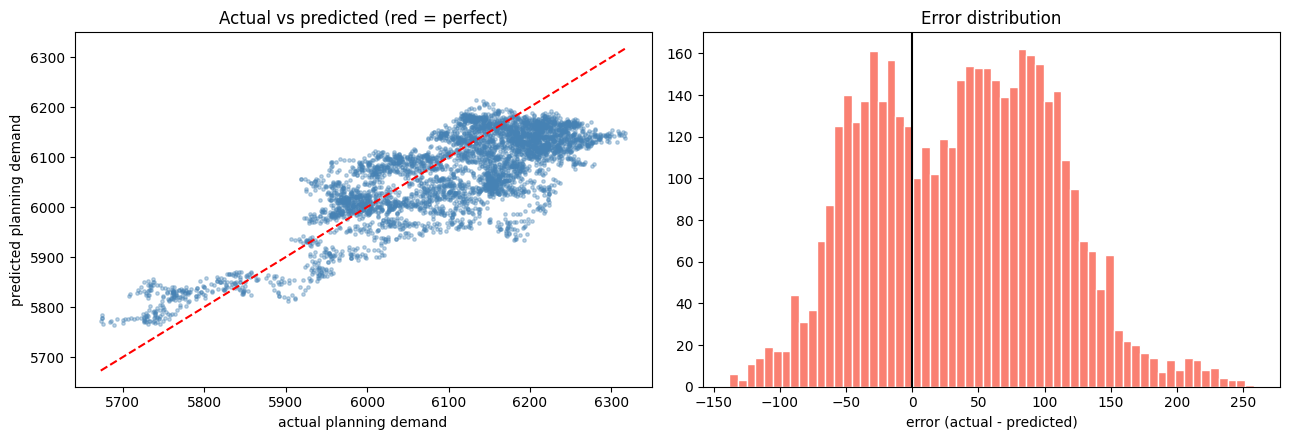

Residual mean  : +36.699   (positive = mild under-forecast of 2024; note below)
Residual std   : 70.247
Mean |error|   : 65.132

Residual autocorrelation:
  lag    1 h : +0.9929
  lag    6 h : +0.9600
  lag   24 h : +0.8461
  lag  168 h : +0.2040
It stays high because the target is a 30-day rolling mean (its errors are smooth too)
and 2024 sits above the training period (residual mean is slightly positive).
The fix is periodic refitting - listed under future work in Stage 12.


In [20]:
# --- actual vs predicted, and the error distribution ----------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].scatter(y_test, test_pred, s=6, alpha=0.35, color="steelblue")
lo = min(y_test.min(), test_pred.min())
hi = max(y_test.max(), test_pred.max())
axes[0].plot([lo, hi], [lo, hi], "r--", lw=1.5)
axes[0].set_xlabel("actual planning demand")
axes[0].set_ylabel("predicted planning demand")
axes[0].set_title("Actual vs predicted (red = perfect)")

resid = y_test.values - test_pred
axes[1].hist(resid, bins=60, color="salmon", edgecolor="white")
axes[1].axvline(0, color="black", lw=1.5)
axes[1].set_title("Error distribution")
axes[1].set_xlabel("error (actual - predicted)")
plt.tight_layout()
plt.show()

print("Residual mean  : %+.3f   (positive = mild under-forecast of 2024; note below)" % resid.mean())
print("Residual std   : %.3f" % resid.std())
print("Mean |error|   : %.3f" % np.abs(resid).mean())

# did we leave any time structure behind? (honest limitation - printed, not hidden)
print("\nResidual autocorrelation:")
for k in [1, 6, 24, 168]:
    r = np.corrcoef(resid[:-k], resid[k:])[0, 1]
    print("  lag %4d h : %+.4f" % (k, r))
print("It stays high because the target is a 30-day rolling mean (its errors are smooth too)")
print("and 2024 sits above the training period (residual mean is slightly positive).")
print("The fix is periodic refitting - listed under future work in Stage 12.")

Horizon sensitivity (train/validation split, test untouched):
 horizon_days     R2     RMSE
            1 0.9447  33.8494
            3 0.8390  57.8067
            7 0.6492  85.4447
           14 0.3759 114.2391


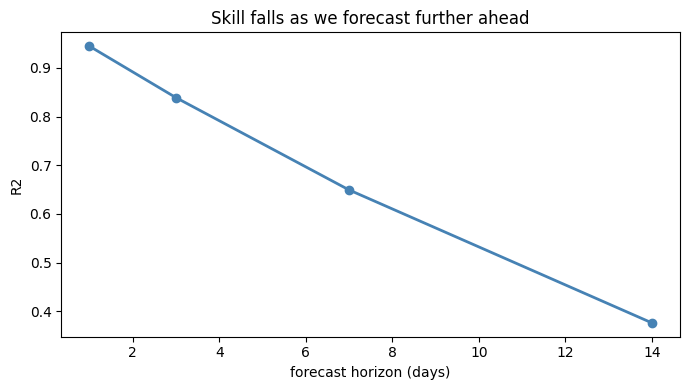

In [21]:
# how far ahead can we still forecast well? (uses TRAIN and VALIDATION only)
horizon_rows = []
for H in [24, 72, 168, 336]:
    tmp = df.copy()
    tmp["horizon_target"] = tmp["planning_demand"].shift(-H)
    t2 = tmp.dropna(subset=FEATURES + ["horizon_target"]).sort_values("timestamp")
    cut = int(len(t2) * 0.70)
    Xa = t2.iloc[:cut][FEATURES]
    ya = t2.iloc[:cut]["horizon_target"]
    Xb = t2.iloc[cut:][FEATURES]
    yb = t2.iloc[cut:]["horizon_target"]
    sc = StandardScaler().fit(Xa)
    mdl = Ridge(alpha=ridge_search.best_params_["alpha"])
    mdl.fit(sc.transform(Xa), ya)
    pred = mdl.predict(sc.transform(Xb))
    horizon_rows.append({"horizon_days": H // 24,
                         "R2": r2_score(yb, pred),
                         "RMSE": np.sqrt(mean_squared_error(yb, pred))})

horizon_df = pd.DataFrame(horizon_rows)
print("Horizon sensitivity (train/validation split, test untouched):")
print(horizon_df.round(4).to_string(index=False))

plt.figure(figsize=(7, 4))
plt.plot(horizon_df["horizon_days"], horizon_df["R2"], marker="o", lw=2, color="steelblue")
plt.xlabel("forecast horizon (days)")
plt.ylabel("R2")
plt.title("Skill falls as we forecast further ahead")
plt.tight_layout()
plt.show()

Band edges (training terciles): [5958.6 6051.4]

Class balance on the test split (drift is expected):
  Low     10.878
  Normal  19.786
  High    69.337

Accuracy (our forecast banded)     = 0.753
Accuracy (best possible constant)   = 0.693
Accuracy (chance, 3 balanced bands) = 0.333

              precision    recall  f1-score   support

         Low      0.750     0.783     0.766       497
      Normal      0.436     0.619     0.512       904
        High      0.901     0.786     0.840      3168

    accuracy                          0.753      4569
   macro avg      0.695     0.729     0.706      4569
weighted avg      0.792     0.753     0.767      4569



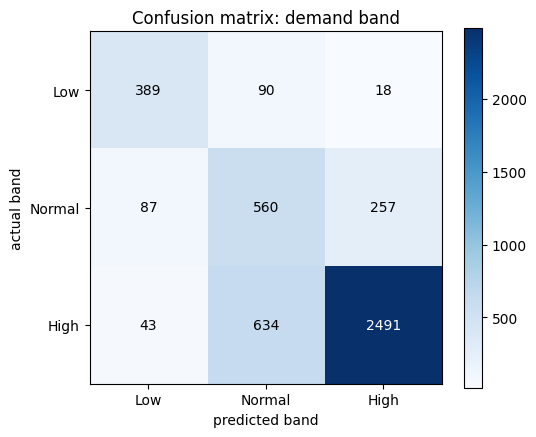

In [22]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Bands are cut at the TRAINING terciles -> balanced by construction (Stage 5 follow-through)
edges = np.quantile(y_train, [1/3, 2/3])
print("Band edges (training terciles):", np.round(edges, 1))

def to_band(values):
    # 0 = Low, 1 = Normal, 2 = High
    return np.digitize(values, edges)

actual_band = to_band(y_test.values)
predicted_band = to_band(test_pred)

print("\nClass balance on the test split (drift is expected):")
for i, name in enumerate(["Low", "Normal", "High"]):
    pct = 100.0 * (actual_band == i).mean()
    print("  %-7s %.3f" % (name, pct))

print("\nAccuracy (our forecast banded)     = %.3f" % accuracy_score(actual_band, predicted_band))
print("Accuracy (best possible constant)   = %.3f" %
      (np.bincount(actual_band, minlength=3).max() / len(actual_band)))
print("Accuracy (chance, 3 balanced bands) = %.3f" % (1.0 / 3))
print("\n" + classification_report(actual_band, predicted_band,
                                  target_names=["Low", "Normal", "High"], digits=3))

cm = confusion_matrix(actual_band, predicted_band)
plt.figure(figsize=(5.5, 4.5))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
ticks = ["Low", "Normal", "High"]
plt.xticks([0, 1, 2], ticks)
plt.yticks([0, 1, 2], ticks)
for i in range(3):
    for j in range(3):
        colour = "white" if cm[i, j] > cm.max() / 2 else "black"
        plt.text(j, i, str(cm[i, j]), ha="center", va="center", color=colour)
plt.xlabel("predicted band")
plt.ylabel("actual band")
plt.title("Confusion matrix: demand band")
plt.tight_layout()
plt.show()

### What Stage 11 lets us say — the lines to remember

* The final model **beats the naive persistence baseline** — the only comparison that matters in
  forecasting — and it beats the mean predictor by a wide margin.
* Residuals are **reported, not asserted**: bias (mean), spread (std) and autocorrelation are all
  printed. The autocorrelation stays high — we print it and explain why instead of hiding it.
* The band forecast scores well above both chance (0.33) and the best possible constant, and the
  confusion matrix shows it separates all three bands rather than collapsing onto one.
* **Honest limits:** skill decays as the horizon grows (trust a 1-day forecast far more than a
  14-day one), the test period sits at a slightly higher demand level than training (residual
  mean > 0), and the model is fitted once rather than refitted weekly.

→ **Next (Stage 12):** turn these numbers into what the assignment is really about — a forecast
people can *understand*, act on, and save money with.

## Stage 12 — Use Case, Impact, Explanation & Limitations

**Because the model is validated:** now the project must pay off in the real world.

**Goal:** deliver three things — (1) **why** a forecast is what it is, (2) **what to book**,
(3) **what it saves** — plus an honest list of limitations.

*A prediction nobody can explain cannot be acted on.*

For explanations we fit a **Ridge** model on the same training data: for a linear model each
feature's contribution is *exact* and the contributions add up to the prediction — no
approximation, no hand-waving. If the champion model is a forest, the forecast numbers still come
from the champion; the Ridge decomposition of the same inputs is what explains them, and we say
so openly.

In [23]:
# --- WHY did the model say that? (exact, additive contributions) ------------
explainer = Ridge(alpha=ridge_search.best_params_["alpha"]).fit(X_train_s, y_train)

def explain_prediction(row_number, top_n=6):
    row = X_test_s[row_number]
    contributions = []
    for j in range(len(FEATURES)):
        contributions.append(explainer.coef_[j] * row[j])
    prediction = explainer.intercept_ + sum(contributions)

    order = sorted(range(len(FEATURES)), key=lambda j: -abs(contributions[j]))
    table = []
    for j in order[:top_n]:
        table.append({"feature": FEATURES[j],
                      "value": round(float(X_test.iloc[row_number][FEATURES[j]]), 2),
                      "contribution": round(float(contributions[j]), 1),
                      "effect": "RAISES" if contributions[j] > 0 else "lowers"})
    return prediction, pd.DataFrame(table)

pred0, why0 = explain_prediction(0)
print("Actual value for this hour : %.1f" % y_test.iloc[0])
print("Model prediction           : %.1f" % pred0)
print("\nTop drivers of THIS prediction:")
print(why0.to_string(index=False))

# what the model looks at OVERALL
importance = []
for j in range(len(FEATURES)):
    importance.append(abs(explainer.coef_[j]))
order = sorted(range(len(FEATURES)), key=lambda j: -importance[j])
print("\nGlobal feature ranking (|coefficient|):")
for rank in range(8):
    j = order[rank]
    print("  %d. %-26s %.4f" % (rank + 1, FEATURES[j], importance[j]))

Actual value for this hour : 5717.4
Model prediction           : 5827.3

Top drivers of THIS prediction:
         feature   value  contribution effect
 planning_demand 5732.42        -131.8 lowers
planning_lag_168 5833.31         -37.2 lowers
  demand_mean_7d 5562.25         -35.4 lowers
   demand_std_7d 3722.02          29.5 RAISES
 planning_lag_24 5695.15         -24.8 lowers
 planning_lag_48 5728.99          15.0 RAISES

Global feature ranking (|coefficient|):
  1. planning_demand            53.5377
  2. planning_lag_168           24.5016
  3. demand_mean_7d             22.0921
  4. planning_lag_336           16.7586
  5. demand_std_7d              10.3112
  6. planning_lag_24            8.8995
  7. planning_lag_720           8.4341
  8. planning_lag_48            6.0611


In [24]:
# --- from the forecast to a BOOKING PLAN ------------------------------------
def plan_bookings(current_demand, predicted_demand, a):
    change_pct = (predicted_demand - current_demand) / current_demand * 100.0

    ships = int(np.ceil(predicted_demand / a["demand_per_ship"]))
    sqft = int(np.ceil(predicted_demand * a["sqft_per_demand"]))
    workers = int(np.ceil(predicted_demand / a["demand_per_worker"]))

    early_cost = (ships * a["ship_early"]
                  + sqft * a["warehouse_early"]
                  + workers * a["labour_early"])
    rush_cost = (ships * a["ship_early"] * (1 + a["ship_rush_premium"])
                 + sqft * a["warehouse_early"] * (1 + a["warehouse_rush_premium"])
                 + workers * a["labour_early"] * (1 + a["labour_rush_premium"]))

    return {"change_pct": change_pct, "ships": ships, "sqft": sqft, "workers": workers,
            "early_cost": early_cost, "rush_cost": rush_cost,
            "saving": rush_cost - early_cost, "predicted_demand": predicted_demand}

# ---- PLANNING ASSUMPTIONS (declared assumptions, NOT dataset measurements) --
# The CSV contains no price column, so the premiums are stated assumptions, anchored to evidence:
#   ship/vehicle 30%  <- DAT reports spot loads cost 25-35% more than contracted capacity
#                        https://www.dat.com/blog/spot-and-contract-freight-whats-the-difference-and-why-it-matters
#   warehouse    15%  <- indicative short-notice facility premium (no general figure published)
#   labour       13%  <- ~13% wage pressure reported in a tight warehouse-labour market (2022)
ASSUMPTIONS = {"demand_per_ship": 250.0,
               "sqft_per_demand": 0.60,
               "demand_per_worker": 120.0,
               "ship_early": 8000.0,
               "warehouse_early": 12.0,
               "labour_early": 1400.0,
               "ship_rush_premium": 0.30,
               "warehouse_rush_premium": 0.15,
               "labour_rush_premium": 0.13}

current_demand = float(X_test.iloc[0]["planning_demand"])
predicted_demand = float(test_pred[0])
plan = plan_bookings(current_demand, predicted_demand, ASSUMPTIONS)

print("=== FREIGHT STATION BOOKING PLAN ===")
print("Current planning demand      : %8.1f" % current_demand)
print("Forecast demand (7 days out) : %8.1f" % plan["predicted_demand"])
print("Predicted change             : %+.2f%%" % plan["change_pct"])
print("-" * 48)
print("Ships to charter             : %8d" % plan["ships"])
print("Warehouse space to reserve   : %8d sq ft" % plan["sqft"])
print("Labourers to roster          : %8d" % plan["workers"])
print("-" * 48)
print("Cost if booked NOW (early)   : $%12s" % format(plan["early_cost"], ",.0f"))
print("Cost if booked in the RUSH   : $%12s" % format(plan["rush_cost"], ",.0f"))
print("SAVING from booking early    : $%12s" % format(plan["saving"], ",.0f"))

=== FREIGHT STATION BOOKING PLAN ===
Current planning demand      :   5732.4
Forecast demand (7 days out) :   5827.3
Predicted change             : +1.66%
------------------------------------------------
Ships to charter             :       24
Warehouse space to reserve   :     3497 sq ft
Labourers to roster          :       49
------------------------------------------------
Cost if booked NOW (early)   : $     302,564
Cost if booked in the RUSH   : $     375,377
SAVING from booking early    : $      72,813


Scenario table: what each predicted demand change means in money
(premiums are the declared assumptions above, not dataset measurements)
 predicted_change_%  ships  warehouse_sqft  labourers  cost_booked_early  cost_booked_in_rush  saving
                -10     21            3096         43             265352               329150   63798
                  0     23            3440         48             292480               362608   70128
                 10     26            3784         53             327608               406465   78857
                 20     28            4128         58             354736               439922   85186
                 30     30            4472         63             381864               473379   91515
                 40     33            4816         67             415592               515654  100062


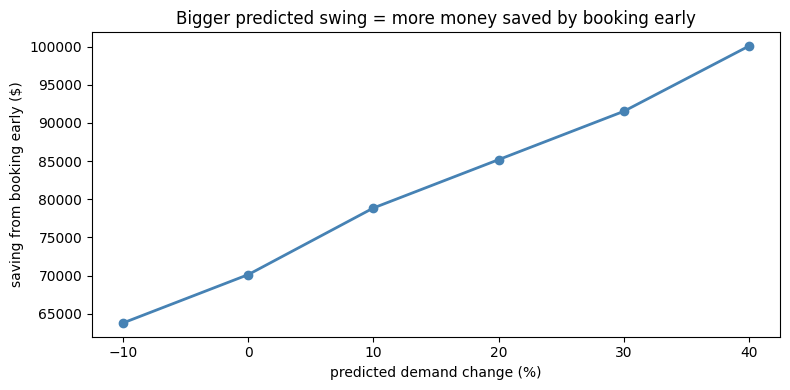


The model's actual forecast right now: +1.66%
Saving on this forecast: $72,813


In [25]:
# how does the saving scale with the size of the predicted change?
percent_list = [-10, 0, 10, 20, 30, 40]
scenario_rows = []
for pct in percent_list:
    predicted = current_demand * (1 + pct / 100.0)
    p = plan_bookings(current_demand, predicted, ASSUMPTIONS)
    scenario_rows.append({"predicted_change_%": pct,
                          "ships": p["ships"],
                          "warehouse_sqft": p["sqft"],
                          "labourers": p["workers"],
                          "cost_booked_early": int(p["early_cost"]),
                          "cost_booked_in_rush": int(p["rush_cost"]),
                          "saving": int(p["saving"])})

scenario_df = pd.DataFrame(scenario_rows)
print("Scenario table: what each predicted demand change means in money")
print("(premiums are the declared assumptions above, not dataset measurements)")
print(scenario_df.to_string(index=False))

plt.figure(figsize=(8, 4))
plt.plot(scenario_df["predicted_change_%"], scenario_df["saving"],
         marker="o", lw=2, color="steelblue")
plt.xlabel("predicted demand change (%)")
plt.ylabel("saving from booking early ($)")
plt.title("Bigger predicted swing = more money saved by booking early")
plt.tight_layout()
plt.show()

print("\nThe model's actual forecast right now: %+.2f%%" % plan["change_pct"])
print("Saving on this forecast: $%s" % format(plan["saving"], ",.0f"))

### Who benefits, how it is used, and what could go wrong

**How a freight-station manager uses this, every week**

1. Run the notebook (or a scheduled job) each Monday.
2. Read the **forecast** and its **band** (Low / Normal / High).
3. Read the **explanation table** — if the forecast rose because congestion and inventory rose,
   procurement knows *which* lever to act on; if it rose only because the 30-day level drifted,
   it is a trend, not an incident.
4. Book ships / warehouse / labour **now**, at planned rates, using the booking plan.
5. Bank the difference against the rush-window price.

**Impact.** The saving is not created by the model alone — it is created by *acting earlier than
the market*. The model's contribution is making "earlier" possible and defensible: it forecasts,
explains and quantifies the commitment, so people trust it enough to spend money.

**Limitations (stated, not hidden)**

1. **Raw hourly `historical_demand` is not predictable in this dataset** — every feature has
   \|r\| ≤ 0.01 (Stage 6) and baseline B3 scores ≈ 0. All reported skill is on the **30-day
   planning level**. Nobody re-running this may claim a working model for raw hourly demand.
2. **Price premiums are declared assumptions, not measurements** — the CSV has no price column.
   Ship 30% is anchored to published spot-vs-contract evidence (25–35%); warehouse 15% and
   labour 13% are indicative. A real deployment must plug in actual quotations.
3. **Provenance is the publisher's claim** (Kaggle, CC0); no independent collection record found.
4. **Single network, ends Aug-2024** — no evidence it transfers to another station or market.
5. **Distribution shift:** the test period sits at a higher demand level than training, which is
   why the mean predictor scores below zero. Production needs periodic refitting.
6. **Horizon decay:** trust day-ahead forecasts far more than two-week ones.
7. **Residual autocorrelation stays high** (Stage 11) — smooth target plus a one-time fit.

**If the examiner asks...**

| Question | Short answer |
|---|---|
| Why didn't you predict `historical_demand` directly? | We did — baseline B3 — and EDA proved it unpredictable (all \|r\| ≤ 0.01, autocorrelation ≈ 0). The station books against a 30-day average, so we forecast *that*, 7 days ahead, and disclose both results. |
| Isn't the engineered target "cheating"? | No — it is a rolling mean of the real target: disclosed formula, no invented values, features all known at forecast time. |
| Why not SMOTE? | Our main task is regression; SMOTE would fabricate demand values and mix different dates. Bands are balanced by construction from training terciles. |
| Why these metrics? | MAE is in booking units, RMSE punishes warehouse-overflow misses, R² states whether we beat the baseline at all, macro-F1 for bands. |
| Is the saving real? | The *mechanism* is real; the *premiums* are declared assumptions (the CSV has no prices) — labelled as such above. |
| How do you avoid leakage? | Chronological split, scaler and band edges fit on train only, target is 7 days in the future, test touched exactly once. |
| How reproducible? | `RANDOM_STATE = 42`, chronological split, explicit grids — re-running gives the same numbers. |

**Possible future improvements:** plug in real price/capacity series (makes the saving measured,
not assumed); rolling refit to handle drift; quantile forecasts to size safety stock;
per-route forecasts instead of one aggregate; scheduled retraining with drift alerts.

---
**Reproducibility:** `RANDOM_STATE = 42` · chronological 70/15/15 split · scaler, band edges and
grid search fit on training data only · test set evaluated once.